In [2]:
# Tools for numbers and charts
import numpy as np
import matplotlib.pyplot as plt

# Tools for the neural networks (MLP and CNN)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Tools for the SVM and for checking results
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load the handwritten digit pictures (built into Keras, no download needed)
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("Training pictures:", X_train.shape)
print("Test pictures:", X_test.shape)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training pictures: (60000, 28, 28)
Test pictures: (10000, 28, 28)
GPU available: True


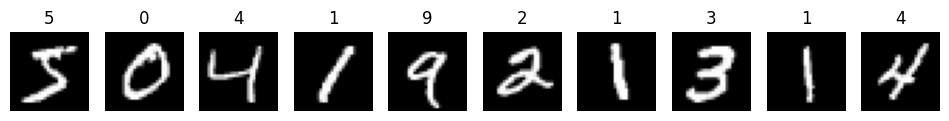

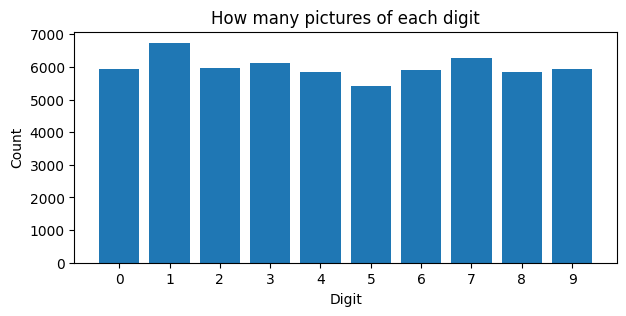

In [3]:
# Show the first 10 pictures with their correct answers
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)          # 1 row, 10 small boxes
    plt.imshow(X_train[i], cmap="gray") # draw the picture in black and white
    plt.title(y_train[i])               # show the correct number on top
    plt.axis("off")                     # hide the axis lines
plt.show()

# How many pictures of each digit do we have?
digits, counts = np.unique(y_train, return_counts=True)
plt.figure(figsize=(7, 3))
plt.bar(digits, counts)
plt.title("How many pictures of each digit")
plt.xlabel("Digit")
plt.ylabel("Count")
plt.xticks(digits)
plt.show()

In [ ]:
## Looking at the data
- 60,000 training pictures and 10,000 test pictures, each 28 x 28 pixels in grayscale.
- Handwriting varies a lot (thick, thin, tilted), which makes the task harder.
- Each digit has about 6,000 pictures, so the dataset is balanced.

In [4]:
# 1. Scale pixels from 0–255 down to 0–1 (models learn better with small numbers)
X_train = X_train / 255.0
X_test = X_test / 255.0

# 2. Flat version (one long list of 784 numbers) for the SVM and MLP
X_train_flat = X_train.reshape(-1, 784)
X_test_flat = X_test.reshape(-1, 784)

# 3. Picture version (28 x 28 with 1 colour channel) for the CNN
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

print("Flat shape (SVM, MLP):", X_train_flat.shape)
print("Picture shape (CNN):", X_train_cnn.shape)
print("Smallest and biggest pixel now:", X_train.min(), X_train.max())

Flat shape (SVM, MLP): (60000, 784)
Picture shape (CNN): (60000, 28, 28, 1)
Smallest and biggest pixel now: 0.0 1.0


In [ ]:
## Preprocessing
- Pixel values scaled from 0–255 to 0–1.
- SVM and MLP use flattened images (784 numbers each).
- CNN keeps the 28 x 28 image shape so it can see shapes and edges.

In [5]:
import time

# SVM is slow on big data, so we train it on 10,000 pictures instead of 60,000
n = 10000

start = time.time()
svm = SVC(kernel="rbf")                       # the fence builder (curved fence)
svm.fit(X_train_flat[:n], y_train[:n])        # learn from 10,000 pictures
svm_pred = svm.predict(X_test_flat)           # guess the 10,000 test pictures
svm_time = time.time() - start

svm_acc = accuracy_score(y_test, svm_pred)    # how many guesses were right
print(f"SVM accuracy: {svm_acc:.4f}")
print(f"Time taken: {svm_time:.1f} seconds")

SVM accuracy: 0.9594
Time taken: 34.8 seconds


In [ ]:
## Model 1: SVM
- RBF kernel, trained on 10,000 images (SVM is slow on the full 60,000).
- Test accuracy: 95 %
- Training + prediction time: 34.8 seconds

In [6]:
# Build Molly: a simple brain with layers
mlp = keras.Sequential([
    layers.Input(shape=(784,)),               # input: 784 numbers (the flat picture)
    layers.Dense(128, activation="relu"),     # hidden layer 1: 128 neurons
    layers.Dense(64, activation="relu"),      # hidden layer 2: 64 neurons
    layers.Dense(10, activation="softmax")    # output: 10 answers (0–9)
])

# Tell Molly how to learn
mlp.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

# Study (train)
start = time.time()
mlp_history = mlp.fit(X_train_flat, y_train, epochs=10, batch_size=128,
                      validation_split=0.1, verbose=1)
mlp_time = time.time() - start

# Test
mlp_loss, mlp_acc = mlp.evaluate(X_test_flat, y_test, verbose=0)
print(f"MLP accuracy: {mlp_acc:.4f}")
print(f"Time taken: {mlp_time:.1f} seconds")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8977 - loss: 0.3626 - val_accuracy: 0.9598 - val_loss: 0.1505
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9550 - loss: 0.1538 - val_accuracy: 0.9680 - val_loss: 0.1112
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9680 - loss: 0.1075 - val_accuracy: 0.9723 - val_loss: 0.0999
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9758 - loss: 0.0823 - val_accuracy: 0.9757 - val_loss: 0.0851
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9811 - loss: 0.0642 - val_accuracy: 0.9748 - val_loss: 0.0917
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9838 - loss: 0.0521 - val_accuracy: 0.9735 - val_loss: 0.0934
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9869 - loss: 0.0425 - val_accuracy: 0.9772 - val_loss: 0.0790
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9896 - loss: 0.0355 - val_accuracy: 0.

In [ ]:
## Model 2: MLP
- 784 inputs → 128 neurons → 64 neurons → 10 outputs, trained for 10 epochs on all 60,000 images.
- Test accuracy: 97 %
- Training time: 22.4 seconds

In [7]:
# Build Charlie: the magnifying-glass brain
cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),                    # input: the real 28x28 picture
    layers.Conv2D(32, (3, 3), activation="relu"),       # magnifying glass: 32 small 3x3 windows look for lines and edges
    layers.MaxPooling2D((2, 2)),                        # shrink the picture, keep the important parts
    layers.Conv2D(64, (3, 3), activation="relu"),       # 64 windows look for bigger shapes (loops, curves)
    layers.MaxPooling2D((2, 2)),                        # shrink again
    layers.Flatten(),                                   # now turn what it found into a list
    layers.Dense(64, activation="relu"),                # small brain to put the clues together
    layers.Dense(10, activation="softmax")              # output: 10 answers (0–9)
])

cnn.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

# Study (train)
start = time.time()
cnn_history = cnn.fit(X_train_cnn, y_train, epochs=10, batch_size=128,
                      validation_split=0.1, verbose=1)
cnn_time = time.time() - start

# Test
cnn_loss, cnn_acc = cnn.evaluate(X_test_cnn, y_test, verbose=0)
print(f"CNN accuracy: {cnn_acc:.4f}")
print(f"Time taken: {cnn_time:.1f} seconds")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9260 - loss: 0.2469 - val_accuracy: 0.9802 - val_loss: 0.0705
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9796 - loss: 0.0666 - val_accuracy: 0.9862 - val_loss: 0.0513
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9853 - loss: 0.0489 - val_accuracy: 0.9875 - val_loss: 0.0455
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9889 - loss: 0.0373 - val_accuracy: 0.9875 - val_loss: 0.0411
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9904 - loss: 0.0308 - val_accuracy: 0.9883 - val_loss: 0.0412
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9919 - loss: 0.0249 - val_accuracy: 0.9893 - val_loss: 0.0397
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9932 - loss: 0.0210 - val_accuracy: 0.9903 - val_loss: 0.0388
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9946 - loss: 0.0167 - val_accuracy: 

In [ ]:
## Model 3: CNN
- 2 convolution layers (32 and 64 filters) + pooling, then dense layers. Trained for 10 epochs on all 60,000 images.
- Test accuracy: 99 %
- Training time: 35 seconds

  Model  Accuracy (%)  Time (seconds)  Training images
0   SVM         95.94           34.80            10000
1   MLP         97.59           22.45            60000
2   CNN         99.07           35.00            60000


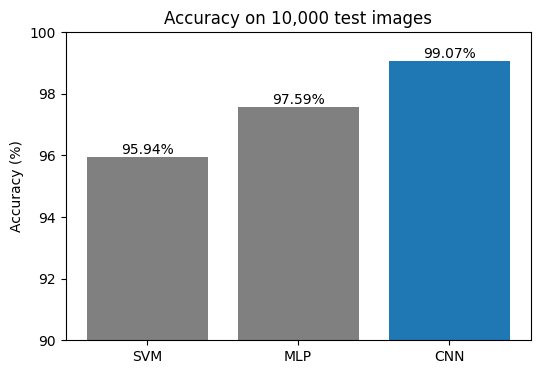

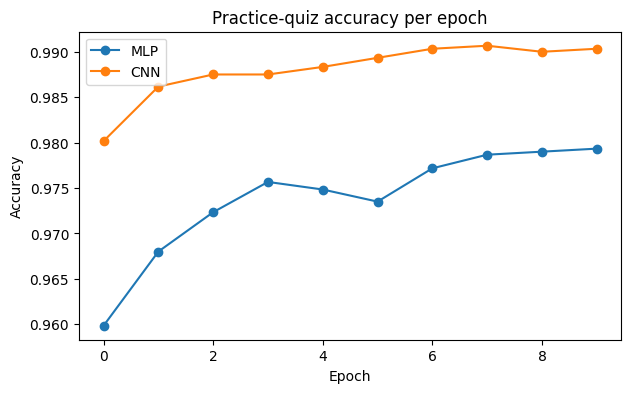

In [8]:
import pandas as pd

# Put all results in one table
results = pd.DataFrame({
    "Model": ["SVM", "MLP", "CNN"],
    "Accuracy (%)": [svm_acc * 100, mlp_acc * 100, cnn_acc * 100],
    "Time (seconds)": [svm_time, mlp_time, cnn_time],
    "Training images": [10000, 60000, 60000],
}).round(2)
print(results)

# Bar chart of accuracy
plt.figure(figsize=(6, 4))
bars = plt.bar(results["Model"], results["Accuracy (%)"], color=["gray", "gray", "tab:blue"])
plt.bar_label(bars, fmt="%.2f%%")          # write the score on top of each bar
plt.ylim(90, 100)                          # zoom in so the differences are visible
plt.title("Accuracy on 10,000 test images")
plt.ylabel("Accuracy (%)")
plt.show()

# Learning curves: how MLP and CNN improved each epoch
plt.figure(figsize=(7, 4))
plt.plot(mlp_history.history["val_accuracy"], marker="o", label="MLP")
plt.plot(cnn_history.history["val_accuracy"], marker="o", label="CNN")
plt.title("Practice-quiz accuracy per epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## Conclusion

| Model | Accuracy | Wrong (of 10,000) |
|---|---|---|
| SVM (10k training images) | 95.94% | ~406 |
| MLP | 97.59% | ~241 |
| CNN | **99.07%** | **~93** |

**Winner: CNN.** It keeps the image as a 28x28 picture and uses small sliding filters to find edges and shapes, so it understands which pixels are next to each other. The SVM and MLP flatten the image into a list of 784 numbers and lose that shape information.

**Learning curves:** the CNN was already at 98% after the first epoch and reached about 99%, while the MLP reached about 98%.

**Trade-offs:** the SVM is slow on large data, so it was trained on only 10,000 images. The CNN needs more computing power, but with a GPU it trained in 35 seconds.

**Next steps:** add data augmentation (small rotations and shifts) or dropout to push the CNN higher.